# Telecom Customer Churn :


- Compare Logistic Regression, Random Forest and XGBoost.
- Evaluate accuracy **and** churn-focused metrics.
- Tune XGBoost using F1 rather than accuracy.
- Analyze the probability threshold for churn.
- Add feature importance and business-oriented churn-risk analysis.

In [1]:
# Import important libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_curve, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

RANDOM_STATE = 42


In [2]:
# Load the dataset
df=pd.read_csv(r'Telco-Customer-Churn.csv')
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


## 1. Prepare a clean modeling dataframe

We remove the customer ID because it is an identifier, not a meaningful predictive feature.

`TotalCharges` is converted to numeric. Blank values become `NaN` and are handled **inside the preprocessing pipeline**, which prevents test-set information from leaking into training.


In [3]:
# Work on a copy so the original dataframe remains unchanged
data = df.copy()

# Remove identifier
if "customerID" in data.columns:
    data = data.drop(columns=["customerID"])

# Convert TotalCharges to numeric
if "TotalCharges" in data.columns:
    data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

# Target encoding
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})

print("Shape:", data.shape)
print("\nMissing values:")
print(data.isna().sum().sort_values(ascending=False).head(10))
print("\nTarget distribution:")
print(data["Churn"].value_counts(normalize=True).rename({0:"No", 1:"Yes"}))


Shape: (7043, 20)

Missing values:
TotalCharges      11
gender             0
Partner            0
SeniorCitizen      0
Dependents         0
tenure             0
MultipleLines      0
PhoneService       0
OnlineSecurity     0
OnlineBackup       0
dtype: int64

Target distribution:
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


## 2. Business-oriented EDA

The following plots focus on variables that can help explain *why* customers churn, rather than only showing generic distributions.



Contract - churn rate (%)
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


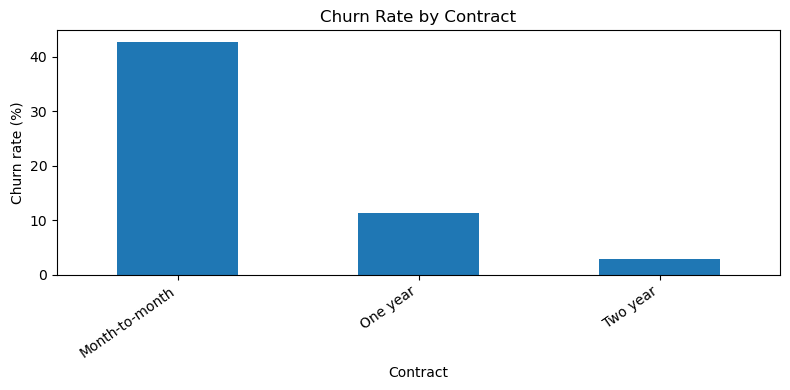


InternetService - churn rate (%)
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64


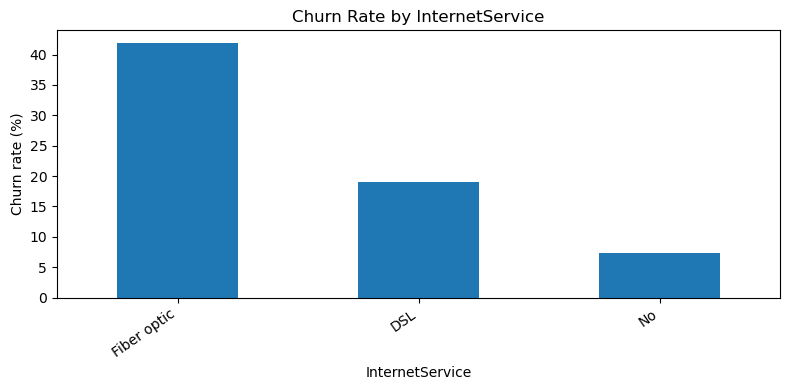


PaymentMethod - churn rate (%)
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


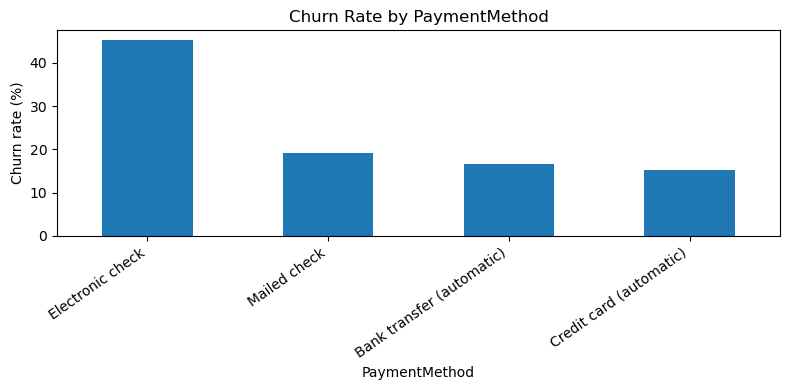


TechSupport - churn rate (%)
TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: Churn, dtype: float64


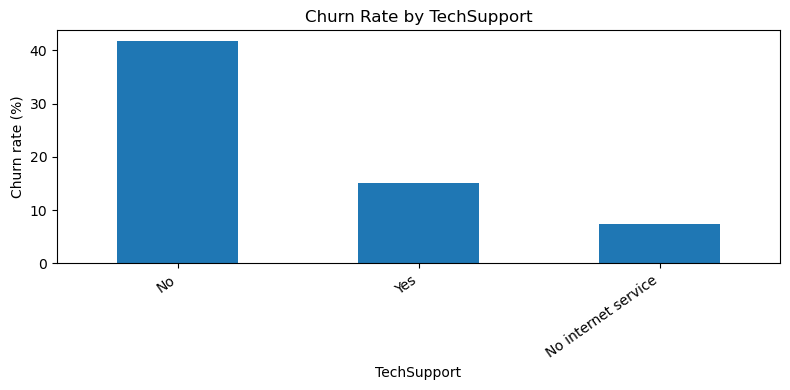


OnlineSecurity - churn rate (%)
OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: Churn, dtype: float64


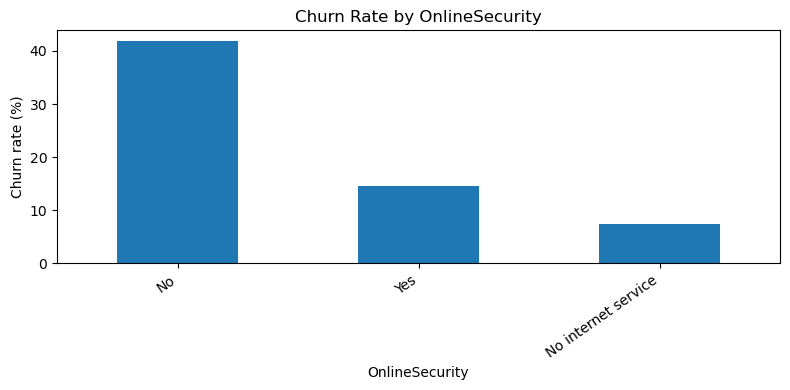


OnlineBackup - churn rate (%)
OnlineBackup
No                     39.93
Yes                    21.53
No internet service     7.40
Name: Churn, dtype: float64


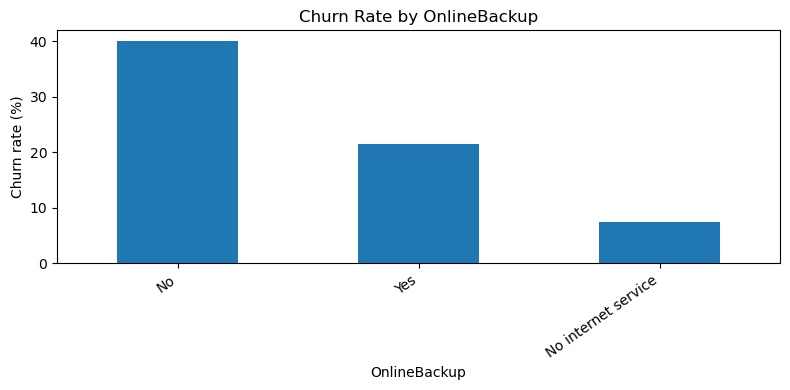

In [4]:
# Helper function: churn rate by category
def churn_rate_by_category(data, column):
    result = data.groupby(column, dropna=False)["Churn"].mean().sort_values(ascending=False)
    return (result * 100).round(2)

eda_cols = [
    c for c in [
        "Contract", "InternetService", "PaymentMethod",
        "TechSupport", "OnlineSecurity", "OnlineBackup"
    ] if c in data.columns
]

for col in eda_cols:
    print(f"\n{col} - churn rate (%)")
    print(churn_rate_by_category(data, col))

    churn_rates = churn_rate_by_category(data, col)
    plt.figure(figsize=(8, 4))
    churn_rates.plot(kind="bar")
    plt.ylabel("Churn rate (%)")
    plt.title(f"Churn Rate by {col}")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()


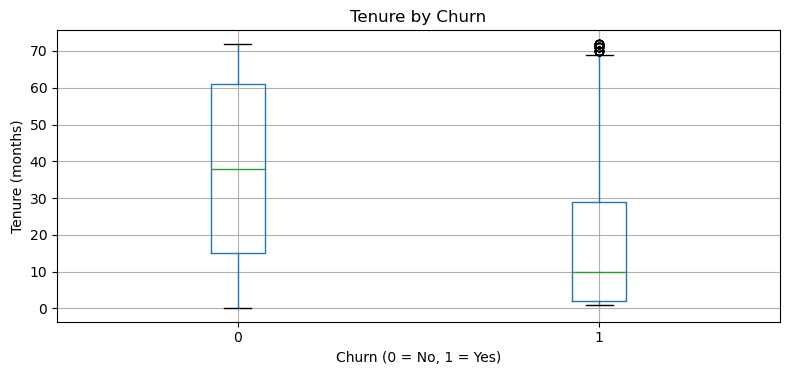

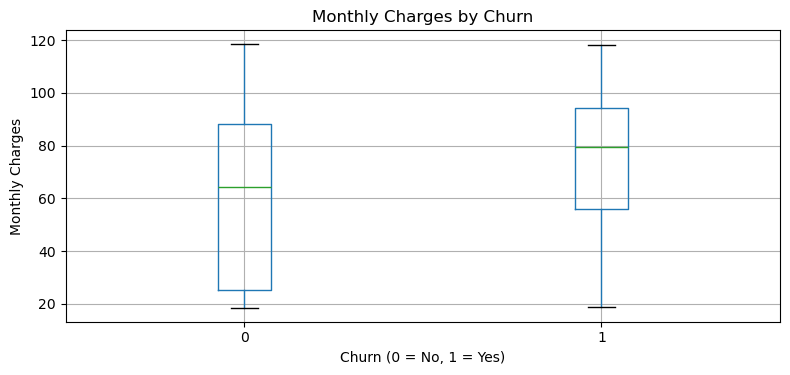

In [5]:
# Tenure and MonthlyCharges by churn
fig, ax = plt.subplots(figsize=(8, 4))
data.boxplot(column="tenure", by="Churn", ax=ax)
ax.set_title("Tenure by Churn")
ax.set_xlabel("Churn (0 = No, 1 = Yes)")
ax.set_ylabel("Tenure (months)")
plt.suptitle("")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
data.boxplot(column="MonthlyCharges", by="Churn", ax=ax)
ax.set_title("Monthly Charges by Churn")
ax.set_xlabel("Churn (0 = No, 1 = Yes)")
ax.set_ylabel("Monthly Charges")
plt.suptitle("")
plt.tight_layout()
plt.show()


### EDA interpretation

For a telecom retention strategy, particular observations are:

1. 'Month to month' contract type has the highest churn rate.
2. Low tenure is the strongest signal for churn risk.
3. High monthly charges are associated with higher churn.
4. Fibre optic internet-service group has the highest churn.
5. Provision of support/security services reduce the churn.
6. Electronic check payment method shows highest churn rate, whereas it is almost similar for other payment methods.


## 3. Train/test split BEFORE fitting preprocessing

This is the key leakage fix.

The imputer and encoders are now fitted only on the training data through the pipeline.


In [6]:
X = data.drop(columns=["Churn"])
y = data["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

categorical_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)


Training shape: (5634, 19)
Test shape: (1409, 19)
Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [7]:
# Robust preprocessing
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols)
])


## 4. Baseline model: Logistic Regression

Logistic Regression provides an interpretable baseline. Tree models can then be judged against it rather than evaluated in isolation.


In [8]:
logreg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logreg_pipeline.fit(X_train, y_train)

def evaluate_model(model, X_test, y_test, name):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, prob)
    }
    print(classification_report(y_test, pred, digits=3))
    return metrics

results = []
results.append(evaluate_model(logreg_pipeline, X_test, y_test, "Logistic Regression"))


              precision    recall  f1-score   support

           0      0.902     0.722     0.802      1035
           1      0.504     0.783     0.614       374

    accuracy                          0.738      1409
   macro avg      0.703     0.753     0.708      1409
weighted avg      0.797     0.738     0.752      1409



## 5. Random Forest comparison


In [9]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=400,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)
results.append(evaluate_model(rf_pipeline, X_test, y_test, "Random Forest"))


              precision    recall  f1-score   support

           0      0.866     0.828     0.846      1035
           1      0.575     0.644     0.608       374

    accuracy                          0.779      1409
   macro avg      0.720     0.736     0.727      1409
weighted avg      0.789     0.779     0.783      1409



## 6. XGBoost model

We use `scale_pos_weight` based on the training class distribution to give the minority churn class more importance.


In [10]:
negative, positive = np.bincount(y_train)
scale_pos_weight = negative / positive

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        scale_pos_weight=scale_pos_weight
    ))
])

xgb_pipeline.fit(X_train, y_train)
results.append(evaluate_model(xgb_pipeline, X_test, y_test, "XGBoost"))


              precision    recall  f1-score   support

           0      0.867     0.783     0.823      1035
           1      0.526     0.668     0.589       374

    accuracy                          0.752      1409
   macro avg      0.697     0.726     0.706      1409
weighted avg      0.777     0.752     0.761      1409



In [11]:
comparison = pd.DataFrame(results).sort_values("F1", ascending=False)
comparison


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.738112,0.504303,0.783422,0.613613,0.841298
1,Random Forest,0.779276,0.575179,0.644385,0.607818,0.834064
2,XGBoost,0.752307,0.526316,0.668449,0.588928,0.818717


## 7. Hyperparameter tuning

For churn prediction, optimizing only for accuracy can favor the majority class. Here we optimize **F1**, which balances precision and recall for the churn class.


In [12]:
param_distributions = {
    "model__n_estimators": np.arange(150, 601, 50),
    "model__max_depth": np.arange(3, 9),
    "model__learning_rate": np.linspace(0.01, 0.20, 20),
    "model__subsample": np.linspace(0.70, 1.00, 7),
    "model__colsample_bytree": np.linspace(0.70, 1.00, 7),
    "model__min_child_weight": np.arange(1, 8),
    "model__gamma": np.linspace(0, 0.4, 9)
}

search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="f1",
    cv=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

best_xgb = search.best_estimator_

print("Best CV F1:", search.best_score_)
print("Best parameters:")
print(search.best_params_)


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best CV F1: 0.6346661386472711
Best parameters:
{'model__subsample': np.float64(0.85), 'model__n_estimators': np.int64(250), 'model__min_child_weight': np.int64(5), 'model__max_depth': np.int64(6), 'model__learning_rate': np.float64(0.02), 'model__gamma': np.float64(0.1), 'model__colsample_bytree': np.float64(0.95)}


In [13]:
tuned_metrics = evaluate_model(best_xgb, X_test, y_test, "Tuned XGBoost")
comparison = pd.concat([comparison, pd.DataFrame([tuned_metrics])], ignore_index=True)
comparison.sort_values("F1", ascending=False)


              precision    recall  f1-score   support

           0      0.902     0.754     0.821      1035
           1      0.531     0.773     0.630       374

    accuracy                          0.759      1409
   macro avg      0.716     0.763     0.725      1409
weighted avg      0.803     0.759     0.770      1409



,Model,Accuracy,Precision,Recall,F1,ROC_AUC
3,Tuned XGBoost,0.758694,0.531250,0.772727,0.629630,0.842327
0,Logistic Regression,0.738112,0.504303,0.783422,0.613613,0.841298
1,Random Forest,0.779276,0.575179,0.644385,0.607818,0.834064
2,XGBoost,0.752307,0.526316,0.668449,0.588928,0.818717


## 8. Confusion matrix for the final model


[[780 255]
 [ 85 289]]


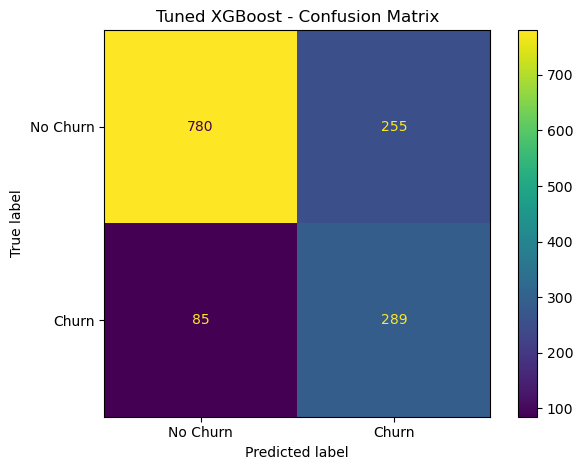

In [14]:
y_pred = best_xgb.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
).plot()
plt.title("Tuned XGBoost - Confusion Matrix")
plt.tight_layout()
plt.show()


## 9. Threshold tuning

`predict()` uses a default probability threshold. For churn prevention, a lower threshold may be worthwhile because missing a true churner can be costly.

The code below compares several thresholds. Select a threshold based on the business cost of false positives versus false negatives.
Lowering the threshold (e.g., to 0.30): Flags more customers as churn risks. This increases Recall (catches more churners) at the cost of lower Precision (more false alarms).

In [15]:
y_prob = best_xgb.predict_proba(X_test)[:, 1]

threshold_rows = []
for threshold in np.arange(0.20, 0.71, 0.05):
    pred_t = (y_prob >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_test, pred_t),
        "Recall": recall_score(y_test, pred_t),
        "F1": f1_score(y_test, pred_t),
        "Accuracy": accuracy_score(y_test, pred_t)
    })

threshold_df = pd.DataFrame(threshold_rows)
threshold_df


,Threshold,Precision,Recall,F1,Accuracy
0,0.20,0.402762,0.935829,0.563154,0.614620
1,0.25,0.430175,0.922460,0.586735,0.655075
2,0.30,0.451220,0.890374,0.598921,0.683463
3,0.35,0.464809,0.847594,0.600379,0.700497
4,0.40,0.490476,0.826203,0.615538,0.726047
5,0.45,0.517241,0.802139,0.628931,0.748758
6,0.50,0.531250,0.772727,0.629630,0.758694
7,0.55,0.553535,0.732620,0.630610,0.772179
8,0.60,0.566292,0.673797,0.615385,0.776437
9,0.65,0.585242,0.614973,0.599739,0.782115


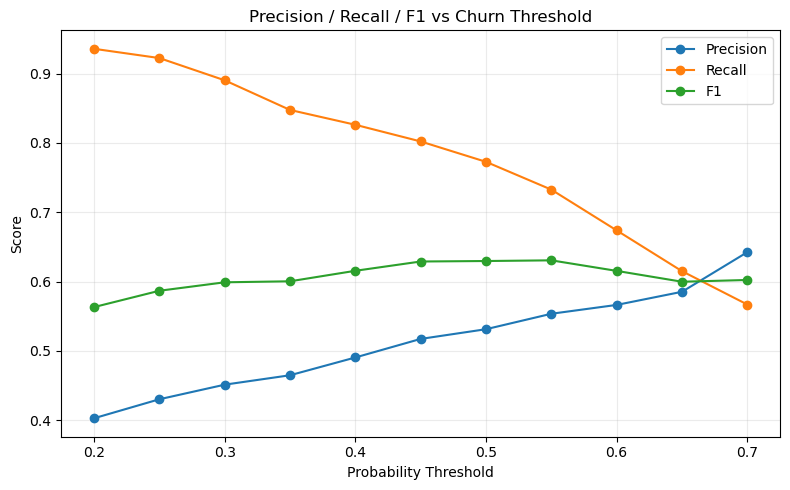

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="o", label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F1"], marker="o", label="F1")
plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Precision / Recall / F1 vs Churn Threshold")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 10. ROC and Precision-Recall curves


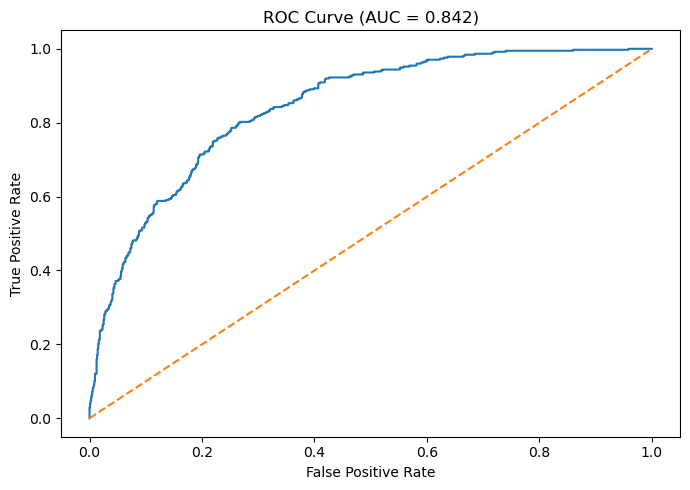

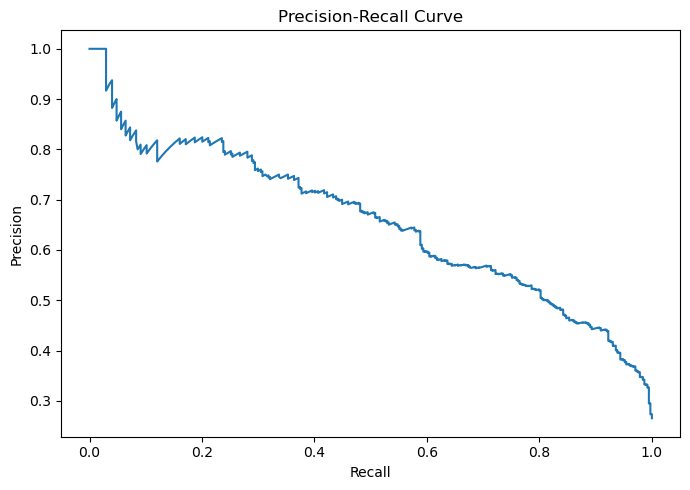

In [17]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
precision, recall, _ = precision_recall_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve (AUC = {roc_auc_score(y_test, y_prob):.3f})")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.tight_layout()
plt.show()


## 11. Feature importance

The following section provides a simple XGBoost feature-importance view.


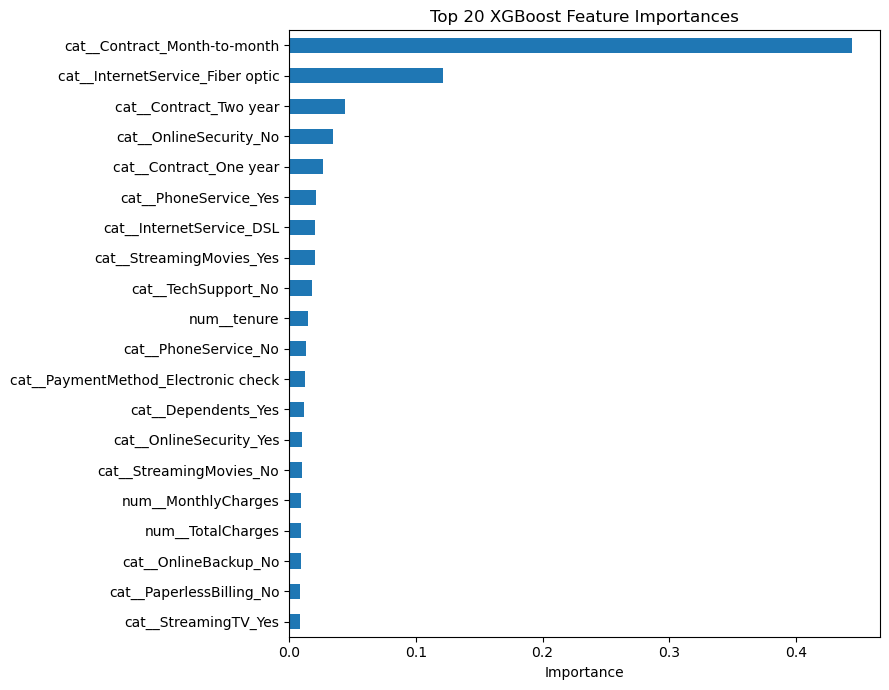

cat__Contract_Month-to-month           0.444135
cat__InternetService_Fiber optic       0.121270
cat__Contract_Two year                 0.044241
cat__OnlineSecurity_No                 0.034683
cat__Contract_One year                 0.026872
cat__PhoneService_Yes                  0.021608
cat__InternetService_DSL               0.020469
cat__StreamingMovies_Yes               0.020462
cat__TechSupport_No                    0.017817
num__tenure                            0.014692
cat__PhoneService_No                   0.013547
cat__PaymentMethod_Electronic check    0.012734
cat__Dependents_Yes                    0.011780
cat__OnlineSecurity_Yes                0.010249
cat__StreamingMovies_No                0.009973
num__MonthlyCharges                    0.009322
num__TotalCharges                      0.009273
cat__OnlineBackup_No                   0.009141
cat__PaperlessBilling_No               0.008587
cat__StreamingTV_Yes                   0.008508
dtype: float32

In [18]:
# Get transformed feature names
pre = best_xgb.named_steps["preprocessor"]
model = best_xgb.named_steps["model"]

feature_names = pre.get_feature_names_out()
importance = pd.Series(model.feature_importances_, index=feature_names)
importance = importance.sort_values(ascending=False)

top_features = importance.head(20).sort_values()

plt.figure(figsize=(9, 7))
top_features.plot(kind="barh")
plt.xlabel("Importance")
plt.title("Top 20 XGBoost Feature Importances")
plt.tight_layout()
plt.show()

top_features.sort_values(ascending=False).head(20)


## 12. Customer-level churn risk

A business application should output a probability, not just 0/1.


In [19]:
customer_risk = X_test.copy()
customer_risk["ActualChurn"] = y_test.values
customer_risk["ChurnProbability"] = y_prob

customer_risk["RiskLevel"] = pd.cut(
    customer_risk["ChurnProbability"],
    bins=[-0.01, 0.30, 0.60, 0.80, 1.00],
    labels=["Low", "Medium", "High", "Very High"]
)

customer_risk.sort_values("ChurnProbability", ascending=False).head(20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,ActualChurn,ChurnProbability,RiskLevel
6623,Male,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,76.45,76.45,1,0.961475,Very High
6866,Male,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,95.45,95.45,1,0.959527,Very High
3380,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,95.10,95.10,1,0.959212,Very High
2464,Female,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,77.15,77.15,1,0.959085,Very High
4585,Female,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,85.05,85.05,1,0.956728,Very High
383,Male,0,No,No,1,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Month-to-month,Yes,Credit card (automatic),90.85,90.85,1,0.949555,Very High
2631,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,99.25,665.45,1,0.948988,Very High
1731,Female,1,No,No,1,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,69.60,69.60,1,0.948728,Very High
2194,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,Yes,No,Month-to-month,Yes,Electronic check,79.50,79.50,1,0.948383,Very High
5706,Female,0,No,No,1,Yes,No,Fiber optic,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,75.70,75.70,1,0.948015,Very High


## Print the customer count according to Risk Level

In [20]:
customer_risk["RiskLevel"].value_counts()

RiskLevel
Low          671
Medium       293
High         252
Very High    193
Name: count, dtype: int64

## 13. Final business interpretation

Use the model to prioritize retention efforts:

- **Very High risk:** immediate retention outreach.
- **High risk:** targeted offer or service intervention.
- **Medium risk:** monitor and communicate proactively.
- **Low risk:** normal customer management.

The model predicts *risk*, not the reason a customer will churn and not a causal effect of any particular service.
